In [1]:
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
from attr.validators import min_len


In [2]:
%load_ext autoreload
%autoreload 2
from src.markov_chains import generate_paths

First I will try a simple two state markov chain

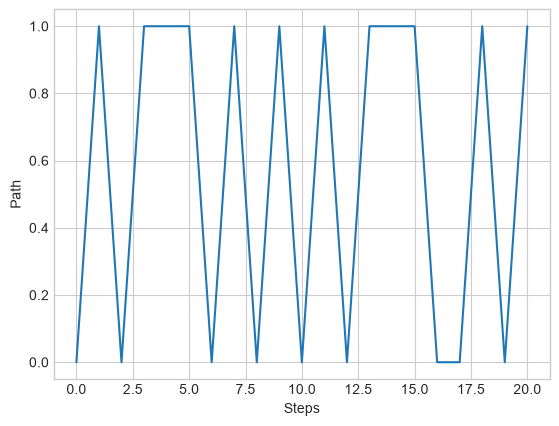

In [3]:
States = [0, 1]
Transition_matrix = np.array([[0.2,0.8], [0.6,0.4]])

steps = 20
current_state = 0
path = np.array([current_state])

for i in range(steps):
    current_state = np.random.choice(States, p=Transition_matrix[current_state])
    path = np.append(path, current_state)

plt.plot(path)
plt.xlabel("Steps")
plt.ylabel("Path")
plt.show()

I will use this same model and calculate the probabilty of the system going from 0 to 1 over 3 steps, using matrix multiplication

In [4]:
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
P3 = np.linalg.matrix_power(transition_matrix, 3)

start_distribution = np.array([0.2,0.4,0.4])
print(np.matmul(start_distribution, P3))
print(P3)

[0.3232 0.2922 0.3846]
[[0.23  0.231 0.539]
 [0.308 0.23  0.462]
 [0.385 0.385 0.23 ]]


In [5]:
states = [0,1,2]
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
start_distribution = np.array([0.2,0.4,0.4])
n_steps = 20


row_vector_of_probabilities = np.matmul(start_distribution, np.linalg.matrix_power(transition_matrix, n_steps))

print(np.matmul(row_vector_of_probabilities, transition_matrix))


[0.313903   0.29148216 0.39461484]


In [6]:
states = [0,1,2]
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
start_distribution = np.array([0.2,0.4,0.4])
n_steps = 20

n_paths = np.linspace(10,10000, 20).astype(int)
ratios0 = []
ratios1 = []
ratios2 = []

for i in n_paths:
    paths = generate_paths(i, n_steps, states, transition_matrix, start_distribution)
    final_positions = paths[:,-1]

    ratio0 = np.sum(final_positions == 0)/len(final_positions)
    ratio1 = np.sum(final_positions == 1)/len(final_positions)
    ratio2 = np.sum(final_positions == 2)/len(final_positions)
    ratios0.append(ratio0)
    ratios1.append(ratio1)
    ratios2.append(ratio2)

row_vector_of_probabilities = np.matmul(start_distribution, np.linalg.matrix_power(transition_matrix, n_steps))

print(row_vector_of_probabilities)
print(ratio0, ratio1, ratio2)

plt.plot(n_paths, ratios0, label = "ratio of paths where the final position is 0")
plt.plot(n_paths, ratios1, label = "ratio of paths where the final position is 1")
plt.plot(n_paths, ratios2, label = "ratio of paths where the final position is 2")
plt.axhline(y=row_vector_of_probabilities[0], linestyle='--', color='r', label = "theoretical probabilities")
plt.axhline(y=row_vector_of_probabilities[1], linestyle='--', color='r')
plt.axhline(y=row_vector_of_probabilities[2], linestyle='--', color='r')
plt.title("Plot of ratio against number of paths")
plt.xlabel("Number of paths")
plt.ylabel("Probability")
plt.legend()




KeyboardInterrupt: 

In [ ]:
states = [0,1,2]
transition_matrix = np.array([[0,0.3,0.7],[0.4,0,0.6],[0.5,0.5,0]])
start_distribution = np.array([0.2,0.4,0.4])
n_steps = np.arange(1, 50)
n_paths = 1000
final_probs = np.empty((0,3))

for i in n_steps:
    row_vector_of_probabilities = np.matmul(start_distribution, np.linalg.matrix_power(transition_matrix, i))
    final_probs = np.vstack((final_probs, row_vector_of_probabilities))


plt.plot(n_steps, final_probs[:,0], label="state 0")
plt.plot(n_steps, final_probs[:,1], label="state 1")
plt.plot(n_steps, final_probs[:,2], label="state 2")
plt.legend()
plt.xlabel("number of steps")
plt.ylabel("Probability")
plt.title("Plot of theoretical probability against number of steps")
plt.show()


now lets try implement gamblers ruin

In [ ]:
p=0.51
m=50
a=20
n_steps= np.arange(1,5000)

P =np.zeros((m+1,m+1))
P[0,0] = 1
P[m,m] = 1
for i in range(1, m):
    P[i,i-1] = 1-p
    P[i,i+1] = p

cdf_ruin = []
cdf_end = []
for i in n_steps:
    row_vector_of_probabilities = np.linalg.matrix_power(P, i)[a]
    probability_of_ruin = row_vector_of_probabilities[0]
    probability_of_end = row_vector_of_probabilities[0] + row_vector_of_probabilities[-1]
    cdf_ruin.append(probability_of_ruin)
    cdf_end.append(probability_of_end)

plt.plot(n_steps, cdf_ruin, color = "blue")
plt.fill_between(x=n_steps, y1=cdf_ruin, y2=0, color = "blue")
plt.xlabel("steps")
plt.ylabel("probability")
plt.title("Cumulative probability of ruin")
plt.axhline(y = 0.3631034,  color = "red", linestyle = "--", label = "theoretical probability of ruin 0.3631034")
plt.legend()
plt.show()
plt.plot(n_steps, cdf_end, color = "red")
plt.fill_between(x=n_steps, y1=cdf_end, y2=0, color = "red")
plt.xlabel("steps")
plt.ylabel("probability")
plt.title("Cumulative Distribution Function for duration")


Poisson processes

In [3]:
from src.poisson_processes import simulate_poisson_process, simulate_multi_processes

Text(0, 0.5, 'count X(t)')

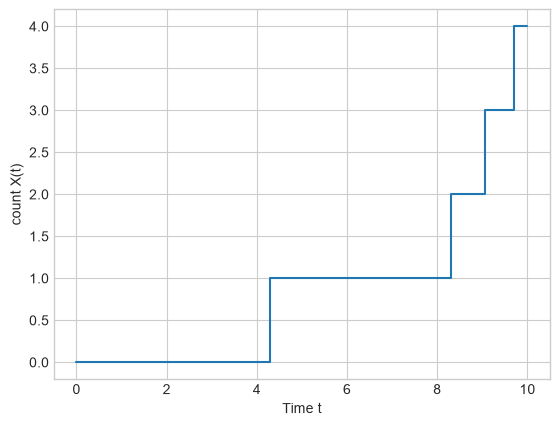

In [29]:
time, position = simulate_poisson_process(0.5, 10)

plt.plot(time, position)
plt.xlabel("Time t")
plt.ylabel("count X(t)")

Text(0.5, 1.0, 'PMF Calculated by simulating 10000 paths, with rate = 0.5 and max time of 10')

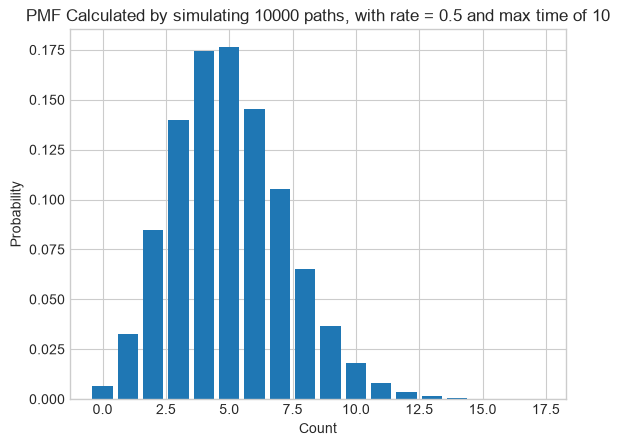

In [87]:
paths = simulate_multi_processes(100000, 0.5, 10)

final_nums = [i[1][-1] for i in paths]

final_nums = np.array(final_nums)
frequency_final_nums = np.bincount(final_nums, minlength=final_nums.max() + 1) / len(final_nums)
x = np.arange(final_nums.max() + 1)


plt.bar(x, frequency_final_nums)
plt.ylabel("Probability")
plt.xlabel("Count")
plt.title("PMF Calculated by simulating 10000 paths, with rate = 0.5 and max time of 10")

In [82]:
import scipy
import scipy.stats
from scipy.stats import poisson

Text(0.5, 1.0, 'Actual PMF for a Poisson(5)')

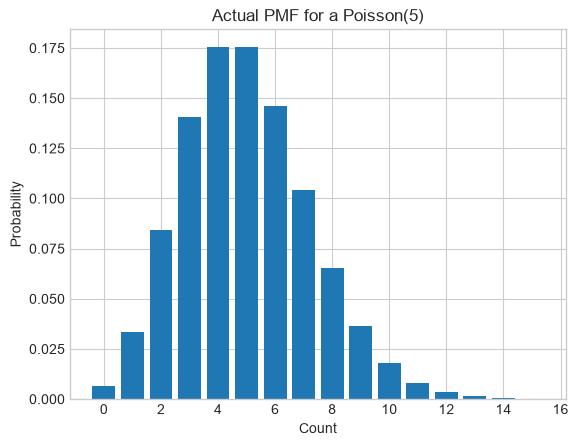

In [83]:
pmf = []
for i in range(0, final_nums.max() + 1):
    p = poisson.pmf(i, 5)
    pmf.append(p)

plt.bar(x, pmf)
plt.xlabel("Count")
plt.ylabel("Probability")
plt.title("Actual PMF for a Poisson(5)")


In [88]:
ex = np.mean(final_nums)
var = np.var(final_nums)
print(ex, var)


5.01168 5.017583577600001


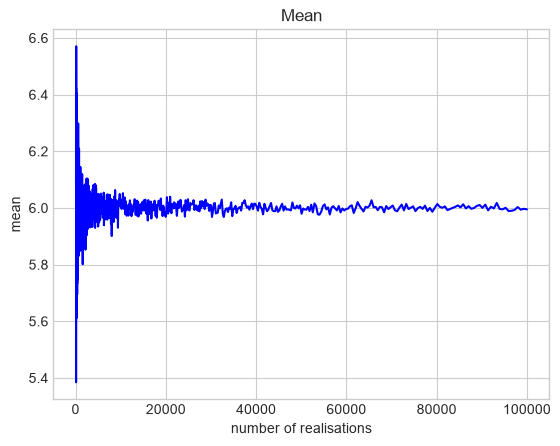

Text(0.5, 1.0, 'variance')

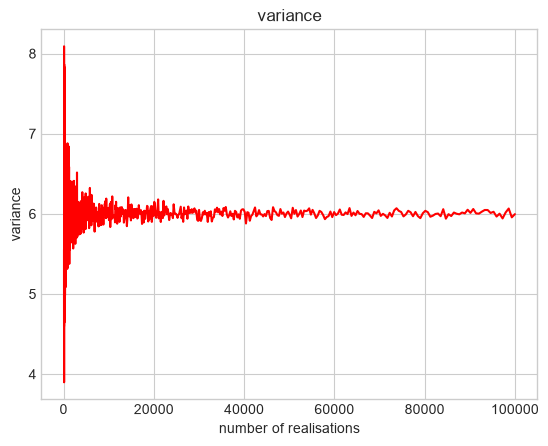

In [117]:
n = np.logspace(2, 5, num=1000).astype(int)
ex = []
var = []
for i in n:
    Xt = poisson.rvs(mu=2,size=i)
    Yt = poisson.rvs(mu=4,size=i)
    Zt = Xt + Yt
    ex.append(np.mean(Zt))
    var.append(np.var(Zt))

plt.plot(n, ex, color = "blue")
plt.xlabel("number of realisations")
plt.ylabel("mean")
plt.title("Mean")
plt.show()
plt.plot(n, var, color = "red")
plt.xlabel("number of realisations")
plt.ylabel("variance")
plt.title("variance")

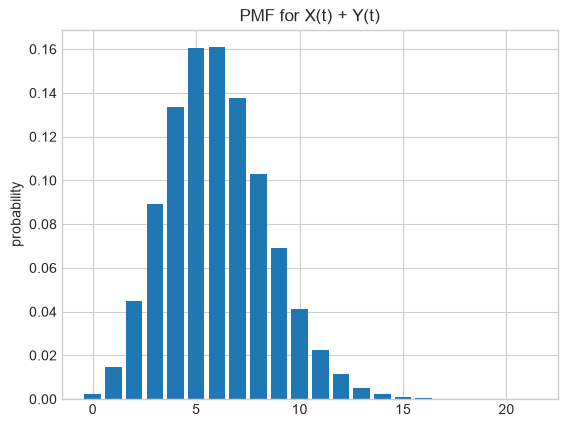

Text(0, 0.5, 'probability')

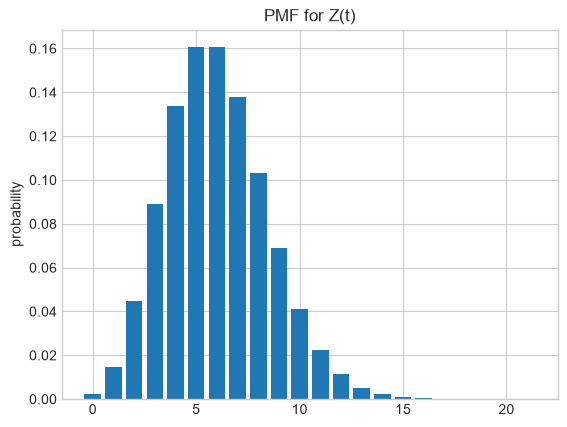

In [127]:
Xt = poisson.rvs(mu=2,size=1000000)
Yt = poisson.rvs(mu=4,size=1000000)
Zt = Xt + Yt
frequency = np.bincount(Zt, minlength=Zt.max() + 1) / len(Zt)
x = np.arange(Zt.max() + 1)

pmf = []
for i in range(0, Zt.max() + 1):
    p = poisson.pmf(i, 6)
    pmf.append(p)

plt.bar(x, frequency)
plt.title("PMF for X(t) + Y(t)")
plt.ylabel("probability")
plt.show()
plt.bar(x, pmf)
plt.title("PMF for Z(t)")
plt.ylabel("probability")

